# Notebook 4: Evaluation
**IDS 560, Group 4, M5 inventory agent (v4).** Checks the numbers behind the agent's orders on 2015–2016 data. No language-model calls; about 10 minutes.

1. **Setup:** loads the M5 data, the forecast cube and the segment files.
2. **New-item simulation:** which way of forecasting new items works best (the winner is saved for notebook 3).
3. **Confidence check:** do Low-confidence forecasts really miss by more than High ones?
4. **Order backtest:** would the recommended orders have covered actual demand?
5. **Save.**

## 1. Setup

In [1]:
!pip -q install sentence-transformers openai pypdf
import sys, importlib
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass
RAG_FILES = "/content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/RAG FILES/"   # rag_common.py lives here
sys.path.insert(0, RAG_FILES)
import rag_common as rc
importlib.reload(rc)
rc.setup(m5=True, forecasts=True, library=False)
from rag_common import *
import matplotlib.pyplot as plt

Mounted at /content/drive
M5 data: 30,490 series x 1,941 days | prices for 79% of series-weeks
Forecast cube: 15,245 series, 72 weekly forecasts (2014-12-31 to 2016-05-12), 14 days each
Segments: 15,245 series | model error by segment: 2,130 rows
Past launches: 16,610 | new-item method: cascade + own sales
Setup done in 39s | files are read from and saved to /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/RAG FILES/ (names end in _v4)


## 2. New-item simulation
A new item has too little history for the forecasting model, so its forecast starts from **similar items** (launched in the 2 years before the decision, whose sales at the same age are already known) and shifts to the item's own sales over 8 weeks. Groupings tested, each on about 3,000 past launches at launch, after 2 weeks and after 4 weeks:

- one fixed group: department + store + price level, department + state + price level, department + state, category + state, or category;
- **cascade** (progressive broadening): start narrow and widen until 5 similar items are found;
- **cascade + own sales**: the cascade, shifting toward the item's own average as its sales come in.

The method with the lowest error (WAPE) on **2012–2014 launches** is chosen and confirmed on **2015 launches**, then saved in `settings_v4.json` so notebook 3 uses it. About 2 minutes.

In [2]:
def simulate_new_items(n_targets=3000, ages=(0, 14, 28), seed=0):
    """Treat past launches as new items and compare grouping methods on their actual 14-day sales."""
    nd = vals.shape[1]
    lo, hi = int(day_index[pd.Timestamp("2012-01-01")]), int(day_index[pd.Timestamp("2015-10-31")])
    pool = np.flatnonzero((L_FIRST >= lo) & (L_FIRST <= hi) & (L_FIRST + max(ages) + 14 <= nd))
    pick = np.random.default_rng(seed).choice(pool, size=min(n_targets, len(pool)), replace=False)
    strategies = [(name, False) for name, _ in GROUP_LEVELS] + [("cascade", False), ("cascade", True)]
    rows = []
    for li in pick:
        r, f = L_ROWS[li], L_FIRST[li]
        for age in ages:
            d_idx = f + age - 1                                            # decided the day before day `age` of sales
            actual = float(vals[r, f + age: f + age + 14].sum())
            for strat, blend in strategies:
                est = new_item_estimate(r, d_idx, strat, blend)
                if est is not None:
                    rows.append({"launch_year": dates[f].year, "age": age, "method": strat + (" + own sales" if blend else ""),
                                 "actual": actual, "forecast": est["total"], "group": est["group"]})
    sim = pd.DataFrame(rows, columns=["launch_year", "age", "method", "actual", "forecast", "group"])
    sim["period"] = np.where(sim["launch_year"] <= 2014, "2012-2014 launches (choose)", "2015 launches (confirm)")
    sim["abs_err"] = (sim["forecast"] - sim["actual"]).abs()
    sim["err"] = sim["forecast"] - sim["actual"]
    return sim

t0 = time.time()
new_item_sim = simulate_new_items()
NEW_ITEM_STRATEGY, NEW_ITEM_BLEND = "cascade", True          # default if the simulation has too few launches
g = new_item_sim.groupby(["method", "period"])[["abs_err", "err", "actual"]].sum()
sim_table = pd.DataFrame({"WAPE_%": 100 * g["abs_err"] / g["actual"], "bias_%": 100 * g["err"] / g["actual"]}).unstack("period").round(1)
display(sim_table)
by_age = new_item_sim.groupby(["method", "age"])[["abs_err", "actual"]].sum()
display((100 * by_age["abs_err"] / by_age["actual"]).unstack("age").round(1).add_prefix("WAPE at age ").rename_axis(None, axis=1))
choose = new_item_sim[new_item_sim["period"].str.startswith("2012")].groupby("method")[["abs_err", "actual"]].sum()
choose = choose[choose["actual"] > 0]
if len(choose):
    best = (choose["abs_err"] / choose["actual"]).idxmin()
    NEW_ITEM_STRATEGY, NEW_ITEM_BLEND = best.replace(" + own sales", ""), best.endswith("own sales")
    rc.NEW_ITEM_STRATEGY, rc.NEW_ITEM_BLEND = NEW_ITEM_STRATEGY, NEW_ITEM_BLEND
    rc.save_setting(NEW_ITEM_STRATEGY=NEW_ITEM_STRATEGY, NEW_ITEM_BLEND=bool(NEW_ITEM_BLEND))
    print(f"Chosen new-item method (lowest WAPE on 2012-2014 launches): {best} | "
          f"{new_item_sim['method'].eq(best).sum():,} forecasts in the simulation ({time.time() - t0:.0f}s)")
else:
    print("Too few past launches to compare methods: using cascade + own sales")

WAPE_%                          \
period               2012-2014 launches (choose) 2015 launches (confirm)   
method                                                                     
cascade                                     77.7                    77.4   
cascade + own sales                         65.5                    64.5   
category                                    79.8                    75.3   
category + state                            79.7                    74.7   
dept + state                                78.6                    75.5   
dept + state + price                        76.6                    77.4   
dept + store + price                        77.8                    77.4   

                                          bias_%                          
period               2012-2014 launches (choose) 2015 launches (confirm)  
method                                                                    
cascade                                    -37.9                   -23.5  
cascade + own sales                        -27.8                   -15.8  
category                                   -49.7                   -24.9  
category + state                           -49.6                   -23.1  
dept + state                               -45.8                   -22.1  
dept + state + price                       -40.1                   -18.8  
dept + store + price                       -37.5                   -23.5

,WAPE at age 0,WAPE at age 14,WAPE at age 28
method,,,
cascade,69.3,81.9,82.0
cascade + own sales,69.3,69.0,58.2
category,72.0,82.9,84.0
category + state,71.9,82.8,84.1
dept + state,70.9,81.5,83.2
dept + state + price,68.5,80.3,81.2
dept + store + price,69.4,82.0,82.1


Chosen new-item method (lowest WAPE on 2012-2014 launches): cascade + own sales | 9,000 forecasts in the simulation (117s)


## 3. Confidence check
All 15,245 series at four weekly forecast dates: each gets the flags and confidence level the agent would give that day (from data up to that day only), and its 14-day LightGBM forecast is compared with what actually sold. If the score works, **Low-confidence forecasts have a higher error (WAPE) than High ones**, and held items are among the hardest to forecast. A few minutes.

  2015-04-01 done (16s)
  2015-08-05 done (31s)
  2015-12-31 done (47s)
  2016-03-31 done (62s)
LightGBM 14-day forecasts by the confidence level given on the forecast date (all four dates):


,series,share_of_series_%,units_sold,WAPE_%,bias_%,inside_P10_P90_%
level,,,,,,
High,5489,9.0,464404.0,52.9,0.0,64.6
Medium,10482,17.2,352180.0,67.2,-1.9,53.4
Low,45009,73.8,314645.0,114.3,-0.3,85.5


By date (WAPE % by level):


level,High,Medium,Low
date,,,
2015-04-01,45.2,66.4,111.8
2015-08-05,53.7,67.8,117.5
2015-12-31,56.9,70.6,115.4
2016-03-31,52.3,64.9,113.3


Held orders vs not held:


,series,share_of_series_%,units_sold,WAPE_%,bias_%,inside_P10_P90_%
order,,,,,,
held,6040,9.9,24784.0,139.9,-11.7,93.4
not held,54940,90.1,1106445.0,73.0,-0.4,76.5


Flags raised: {'POSSIBLY_DISCONTINUED': 3332, 'POSSIBLE_STOCKOUT': 2262, 'STALE_SEGMENT': 1526, 'NEW_ITEM': 446}

WAPE High 52.9% vs Low 114.3%: the levels separate easy and hard forecasts.


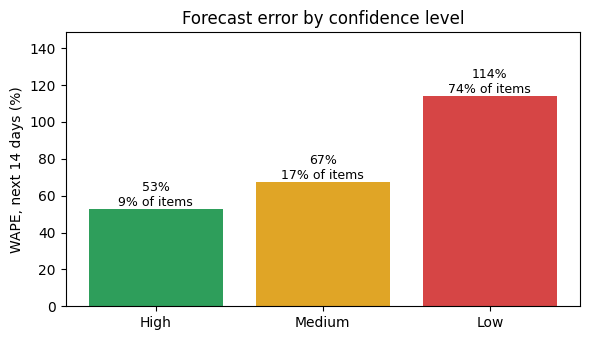

In [3]:
CHECK_DATES = ["2015-04-01", "2015-08-05", "2015-12-31", "2016-03-31"]       # weekly forecast dates in the cube
t0 = time.time()
check_rows = []
for d in [pd.Timestamp(x) for x in CHECK_DATES]:
    if CUBE is None or d not in CUBE["origins"]:
        print("not a forecast date in the cube, skipped:", d.date()); continue
    end = int(day_index[d])
    for sid in CUBE["row"]:
        item, store = split_series_id(sid)
        if not has_series(item, store):
            continue
        fc_c = lightgbm_forecast(item, store, d)
        seg_c = segment_of(item, store)
        h_c = sales_history(item, store, d)
        fl_c = item_flags(item, store, d, seg_c)
        conf_c = forecast_confidence(fc_c, seg_c, fl_c, d, h_c)
        n = min(ORDER_DAYS, vals.shape[1] - end - 1)
        actual = vals[h_c["row"], end + 1: end + 1 + n].astype(float)
        f = fc_c["mean"][:n]
        check_rows.append({"date": d.date(), "series_id": sid, "level": conf_c["level"], "points": conf_c["points"],
                           "hold": any(x["hold"] for x in fl_c), "flags": ", ".join(x["code"] for x in fl_c),
                           "demand_type": seg_c["demand_type"], "volume_level": seg_c["volume_level"], "actual": actual.sum(),
                           "abs_error": np.abs(f - actual).sum(), "signed_error": (f - actual).sum(),
                           "inside": int(((actual >= fc_c["p10"][:n]) & (actual <= fc_c["p90"][:n])).sum()), "days": n})
    print(f"  {d.date()} done ({time.time() - t0:.0f}s)")
conf_check = pd.DataFrame(check_rows)

def conf_table(df, by):
    g = df.groupby(by).agg(series=("series_id", "size"), units_sold=("actual", "sum"), abs_error=("abs_error", "sum"),
                           signed_error=("signed_error", "sum"), inside=("inside", "sum"), days=("days", "sum"))
    g["share_of_series_%"] = 100 * g["series"] / len(df)
    g["WAPE_%"] = 100 * g["abs_error"] / g["units_sold"]
    g["bias_%"] = 100 * g["signed_error"] / g["units_sold"]
    g["inside_P10_P90_%"] = 100 * g["inside"] / g["days"]
    return g[["series", "share_of_series_%", "units_sold", "WAPE_%", "bias_%", "inside_P10_P90_%"]].round(1)

if len(conf_check):
    by_level = conf_table(conf_check, "level").reindex(["High", "Medium", "Low"]).dropna(how="all")
    print("LightGBM 14-day forecasts by the confidence level given on the forecast date (all four dates):")
    display(by_level)
    print("By date (WAPE % by level):")
    display(conf_table(conf_check, ["date", "level"])["WAPE_%"].unstack("level").reindex(columns=["High", "Medium", "Low"]))
    print("Held orders vs not held:")
    display(conf_table(conf_check.assign(order=np.where(conf_check["hold"], "held", "not held")), "order"))
    print("Flags raised:", conf_check["flags"].str.split(", ").explode().replace("", np.nan).dropna().value_counts().to_dict())
    w = by_level["WAPE_%"]
    if {"High", "Low"} <= set(w.index):
        print(f"\nWAPE High {w['High']:.1f}% vs Low {w['Low']:.1f}%: "
              + ("the levels separate easy and hard forecasts." if w["Low"] > w["High"] else "CHECK: Low is not worse than High."))
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.bar(by_level.index, by_level["WAPE_%"], color=["#2E9E5B", "#E0A526", "#D64545"][: len(by_level)])
    for i, (lv, r) in enumerate(by_level.iterrows()):
        ax.text(i, r["WAPE_%"], f"{r['WAPE_%']:.0f}%\n{r['share_of_series_%']:.0f}% of items", ha="center", va="bottom", fontsize=9)
    ax.set_ylabel("WAPE, next 14 days (%)"); ax.set_title("Forecast error by confidence level")
    ax.set_ylim(0, by_level["WAPE_%"].max() * 1.3); plt.tight_layout()
    fig.savefig(out_path("confidence_check.png"), dpi=200, bbox_inches="tight"); plt.show()
else:
    print("No forecasts found for the check dates: put forecast_cube_lightgbm_50.npz in", FORECAST_DIR)

## 4. Order backtest: would the recommended order have covered actual demand?
Notebook 3 checks the explanations and section 2 the forecasts. This checks the **order quantity**. On eight weekly forecast dates spread over 2015–2016, every series in the forecasting model's sample gets the agent's order (same `place_order()` as the scenarios: LightGBM forecast, safety stock, flags, hold rule, new-item forecast), and the order is compared with what actually sold in the next 14 days.

Stock on hand is set to 0, so the order equals the **order-up-to level** (expected demand + safety stock); with any stock on hand the order shrinks by the same amount, so coverage doesn't depend on that assumption.

| Measure | Meaning | Target |
|---|---|---|
| `covered_%` | Share of orders at least as large as the next 14 days' actual sales | about 95% (the service level) |
| `covered_forecast_only_%` | Same, ordering only the forecast with no safety stock | for comparison (about 50% expected) |
| `fill_rate_%` | Share of actual units the order would have covered | close to 100% |
| `leftover_days` | Units left over after 14 days, in days of average demand | lower is better (the cost of the buffer) |

**Held orders** (recommendation 0) are reported separately: for possible stock-outs and possibly discontinued items, the share that sold nothing in the next 14 days shows whether holding was right; for new items, the coverage of the "if confirmed" quantity from the new-item forecast. Takes several minutes (`BACKTEST_DATES` and `BACKTEST_SERIES` make it shorter).

  2014-12-31: done (30s)
  2015-03-11: done (59s)
  2015-05-20: done (88s)
  2015-07-29: done (116s)
  2015-10-07: done (144s)
  2015-12-16: done (172s)
  2016-02-25: done (201s)
  2016-05-05: done (230s)
121,960 orders on 8 dates (109,465 not held)

Orders that were not held, overall and by confidence level (target: about 95% covered):


,orders,covered_%,covered_forecast_only_%,fill_rate_%,leftover_days
all orders,109465,97.3,65.5,98.8,11.3
High,11559,96.6,55.0,99.1,8.9
Medium,22213,96.9,59.6,98.7,10.7
Low,75693,97.5,68.8,98.3,16.3


By category and by demand type:


,orders,covered_%,covered_forecast_only_%,fill_rate_%,leftover_days
FOODS,49795,97.0,62.8,98.8,10.9
HOBBIES,21278,97.7,69.1,98.8,13.8
HOUSEHOLD,38392,97.4,66.9,98.7,11.4
Erratic,3134,96.6,57.1,98.7,10.7
Intermittent,78091,97.5,67.5,98.6,13.1
Lumpy,18271,96.7,62.5,98.5,13.0
No sales,2374,95.0,64.9,97.3,11.1
Smooth,7595,97.3,56.0,99.3,7.7


By date:


,orders,covered_%,covered_forecast_only_%,fill_rate_%,leftover_days
date,,,,,
2014-12-31,12672,97.3,67.9,98.8,12.8
2015-03-11,13462,96.9,66.8,98.5,12.4
2015-05-20,13565,97.3,65.2,98.9,11.5
2015-07-29,13553,96.6,62.7,98.8,10.0
2015-10-07,13872,97.3,64.6,98.7,11.4
2015-12-16,13599,97.9,70.6,98.7,13.0
2016-02-25,14005,97.3,63.1,99.1,10.3
2016-05-05,14737,97.4,63.3,98.7,10.1


Held orders, by flag: share that sold nothing in the next 14 days, and coverage of the 'if confirmed' quantity:


,orders,sold_nothing_pct,avg_units_sold,covered_%,fill_rate_%,leftover_days
flag,,,,,,
NEW_ITEM,1504,63.4,4.1,96.5,90.8,95.2
POSSIBLE_STOCKOUT,4420,66.8,7.0,96.4,85.7,47.3
POSSIBLY_DISCONTINUED,6571,80.0,1.9,96.1,80.3,82.5



Overall: 97.3% of orders covered the next 14 days' sales (target about 95%); ordering the forecast alone would have covered 65.5%.


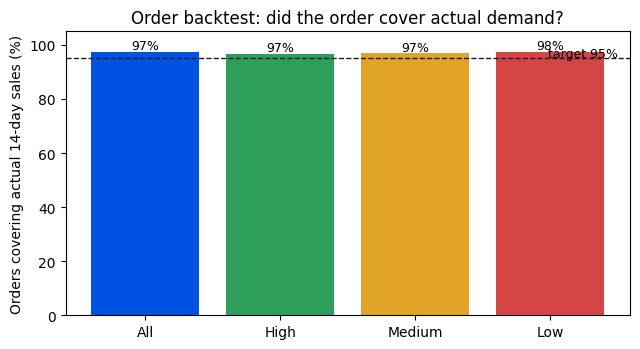

In [4]:
BACKTEST_DATES = 8              # weekly forecast dates, evenly spread over 2015-2016
BACKTEST_SERIES = None          # None = every series in the sample; e.g. 3000 for a quicker run
t0 = time.time()
bt_rows = []
if CUBE is not None:
    full = [d for d in CUBE["origins"] if int(day_index[d]) + ORDER_DAYS < vals.shape[1]]      # 14 days of actual sales known
    bt_dates = [full[i] for i in np.linspace(0, len(full) - 1, BACKTEST_DATES).round().astype(int)]
    series = sorted(CUBE["row"])
    if BACKTEST_SERIES:
        series = list(np.random.default_rng(0).choice(series, size=min(BACKTEST_SERIES, len(series)), replace=False))
    for d in bt_dates:
        end = int(day_index[d])
        for sid in series:
            item, store = split_series_id(sid)
            if not has_series(item, store):
                continue
            try:
                po = place_order(item, store, d, on_hand=0)
            except ValueError:
                continue
            q, fc_b = po["order"], po["forecast"]
            actual = float(vals[po["history"]["row"], end + 1: end + 1 + ORDER_DAYS].sum())
            qty = q["if_confirmed_order_qty"] if q["hold"] else q["order_qty"]
            bt_rows.append({"date": d.date(), "series_id": sid, "category": item.split("_")[0], "demand_type": po["segment"]["demand_type"],
                            "confidence": po["confidence"]["level"], "hold": q["hold"],
                            "flag": ", ".join(f["code"] for f in po["flags"] if f["hold"]) or "none",
                            "order_qty": qty, "forecast_qty": float(np.sum(fc_b["mean"][:ORDER_DAYS])), "actual": actual})
        print(f"  {d.date()}: done ({time.time() - t0:.0f}s)")
backtest = pd.DataFrame(bt_rows)

def coverage_table(df, by):
    d = df.assign(covered=df["order_qty"] >= df["actual"], covered_fc=np.ceil(df["forecast_qty"]) >= df["actual"],
                  short=(df["actual"] - df["order_qty"]).clip(lower=0), left=(df["order_qty"] - df["actual"]).clip(lower=0))
    g = d.groupby(by).agg(orders=("series_id", "size"), covered=("covered", "mean"), covered_fc=("covered_fc", "mean"),
                          actual=("actual", "sum"), short=("short", "sum"), left=("left", "sum"))
    out = pd.DataFrame({"orders": g["orders"], "covered_%": 100 * g["covered"], "covered_forecast_only_%": 100 * g["covered_fc"],
                        "fill_rate_%": 100 * (1 - g["short"] / g["actual"].where(g["actual"] > 0)),
                        "leftover_days": g["left"] / (g["actual"] / ORDER_DAYS).where(g["actual"] > 0)})
    return out.round(1)

if len(backtest):
    active = backtest[~backtest["hold"]]
    print(f"{len(backtest):,} orders on {backtest['date'].nunique()} dates ({len(active):,} not held)\n")
    print("Orders that were not held, overall and by confidence level (target: about 95% covered):")
    bt_overall = coverage_table(active.assign(all="all orders"), "all")
    bt_conf = coverage_table(active, "confidence").reindex(["High", "Medium", "Low"]).dropna(how="all")
    display(pd.concat([bt_overall, bt_conf]))
    print("By category and by demand type:")
    display(pd.concat([coverage_table(active, "category"), coverage_table(active, "demand_type")]))
    print("By date:")
    display(coverage_table(active, "date"))
    held = backtest[backtest["hold"]]
    if len(held):
        print("Held orders, by flag: share that sold nothing in the next 14 days, and coverage of the 'if confirmed' quantity:")
        bt_held = held.groupby("flag").agg(orders=("series_id", "size"), sold_nothing_pct=("actual", lambda x: 100 * (x == 0).mean()),
                                           avg_units_sold=("actual", "mean"))
        bt_held = bt_held.join(coverage_table(held, "flag")[["covered_%", "fill_rate_%", "leftover_days"]]).round(1)
        display(bt_held)
    c = bt_overall["covered_%"].iloc[0]
    print(f"\nOverall: {c:.1f}% of orders covered the next 14 days' sales (target about 95%); "
          f"ordering the forecast alone would have covered {bt_overall['covered_forecast_only_%'].iloc[0]:.1f}%.")
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    labels = ["All"] + list(bt_conf.index)
    vals_c = [c] + list(bt_conf["covered_%"])
    ax.bar(labels, vals_c, color=["#0053E2"] + ["#2E9E5B", "#E0A526", "#D64545"][: len(bt_conf)])
    ax.axhline(95, color="#0F1B30", linestyle="--", linewidth=1); ax.text(len(labels) - 0.5, 95.5, "target 95%", ha="right", fontsize=9)
    for i, v in enumerate(vals_c):
        ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
    ax.set_ylim(0, 105); ax.set_ylabel("Orders covering actual 14-day sales (%)")
    ax.set_title("Order backtest: did the order cover actual demand?")
    plt.tight_layout(); fig.savefig(out_path("order_backtest.png"), dpi=200, bbox_inches="tight"); plt.show()
else:
    print("No forecast cube found: the order backtest needs forecast_cube_lightgbm_50.npz in", FORECAST_DIR)

## 5. Save
| File | What it shows |
|---|---|
| `new_item_simulation_v4.csv` | New-item forecast error (WAPE, bias) by method, 2012–2014 and 2015 launches |
| `confidence_check_v4.csv` / `.png` | Forecast error by confidence level |
| `order_backtest_v4.csv` / `.png` | Order coverage of actual demand, by confidence, category, demand type, date and flag |

In [5]:
saved = []
def save(df, name, **kw):
    df.to_csv(out_path(name), **kw); saved.append(name)
save(sim_table, "new_item_simulation.csv")
if len(conf_check):
    save(conf_table(conf_check, "level"), "confidence_check.csv"); saved.append("confidence_check.png")
if len(backtest):
    save(backtest, "order_backtest.csv", index=False); saved.append("order_backtest.png")
print("Saved to", RAG_DIR + ":", ", ".join(os.path.basename(out_path(n)) for n in saved))

Saved to /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/RAG FILES/: new_item_simulation_v4.csv, confidence_check_v4.csv, confidence_check_v4.png, order_backtest_v4.csv, order_backtest_v4.png
